In [36]:
import os
import random
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pandas as pd

from scipy.optimize import brentq

# Add project source to path
sys.path.append(
    os.path.join(
        '..',  # notes -> root
    )
)

import fig_settings as fs

fs.set_colors()
fs.set_fonts()

In [37]:
# params (to match Fig 2)
PARAMS = dict(
    N = 256,
    avg_deg = 18,
    eps = 0.9, 
    omega = 0.1,
    beta1 = 0.01,
    gamma = 0.1
)

MIN_PREV = 1E-4 # minimum endemic prevalence

In [38]:
def edge_probs(delta, eps, avg_deg, N):
    base = avg_deg / (N - 1.0)
    p11 = (1.0 + delta) * (1.0 + eps) * base   # within block 1
    p22 = (1.0 - delta) * (1.0 + eps) * base   # within block 2
    p12 = (1.0 - eps) * base                   # between blocks
    return p11, p22, p12

def solve_fixed_point(delta, beta1, beta2, eps, omega, avg_deg, N, gamma,
                      max_iter=20000, tol=1e-13, rho0=0.5):
    p11, p22, p12 = edge_probs(delta, eps, avg_deg, N)
    half = N / 2.0
    betas = (beta1, beta2)

    # rho is indexed rho[g, l]
    rho = np.full((2, 2), rho0, dtype=float)

    def lambdas(r):
        rb1 = (1 - omega) * r[0, 0] + omega * r[0, 1]   # aggregate prevalence, block 1
        rb2 = omega * r[1, 0] + (1 - omega) * r[1, 1]   # aggregate prevalence, block 2
        lam1 = (half - 1.0) * p11 * rb1 + half * p12 * rb2
        lam2 = half * p12 * rb1 + (half - 1.0) * p22 * rb2
        return lam1, lam2

    converged = False
    for _ in range(max_iter):
        lam1, lam2 = lambdas(rho)
        lam = (lam1, lam2)
        new = np.empty((2, 2))
        for g in range(2):
            for l in range(2):
                A = 1.0 - np.exp(-betas[l] * lam[g])   # 1 - exp(-beta_l lambda_g)
                new[g, l] = A / (gamma + A)            # rho* = A/(gamma+A)
        if np.max(np.abs(new - rho)) < tol:
            rho = new
            converged = True
            break
        rho = new

    lam1, lam2 = lambdas(rho)
    return rho, lam1, lam2, converged

def F_of_delta(delta, beta2, p):
    rho, lam1, lam2, _ = solve_fixed_point(
        delta, p["beta1"], beta2, p["eps"], p["omega"], p["avg_deg"], p["N"], p["gamma"])
    if rho.max() < MIN_PREV:      # sub-critical / extinct -> F undefined
        return np.nan
    return lam2 - lam1

def find_delta_stars(beta2, p, dmin=-0.95, dmax=0.95, ngrid=241):
    ds = np.linspace(dmin, dmax, ngrid)
    Fs = np.array([F_of_delta(d, beta2, p) for d in ds])
    roots = []
    for i in range(len(ds) - 1):
        a, b = Fs[i], Fs[i + 1]
        if np.isnan(a) or np.isnan(b):
            continue
        if a == 0.0:
            roots.append(ds[i])
        elif a * b < 0.0:
            try:
                r = brentq(lambda x: F_of_delta(x, beta2, p), ds[i], ds[i + 1], xtol=1e-7)
                roots.append(r)
            except (ValueError, RuntimeError):
                pass
    return roots

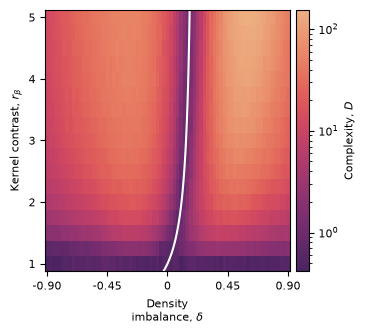

In [39]:
RESULTS_DIR = Path("../results/complexity/")

def edges_extent(piv):
    x = piv.columns.values.astype(float)   # delta
    y = piv.index.values.astype(float)     # beta2
    dx = np.diff(x)[0]
    dy = np.diff(y)[0]
    return (x[0] - dx / 2, x[-1] + dx / 2,
            y[0] - dy / 2, y[-1] + dy / 2), dx, dy

fig, ax = plt.subplots(figsize=(3.8, 3.4))

# load heatmap data
fpath = RESULTS_DIR / "beta_delta_sweep" / "complexity_by_setting.parquet"
df = pd.read_parquet(fpath)
piv = df.pivot(index="beta2", columns="delta", values="complexity_mean")
piv = piv.sort_index().sort_index(axis=1); piv.index = piv.index / PARAMS["beta1"]
(x0, x1, y0, y1), dx, dy = edges_extent(piv)

# beta/delta heatmap
norm = mcolors.LogNorm()
im = ax.imshow(piv.values, 
               cmap=fs.complexity_cmap, 
               aspect="auto", 
               norm=norm, 
               origin="lower",
               extent=(x0, x1, y0, y1))

ax.set_xlabel("Density\nimbalance, $\\delta$")
ax.set_ylabel("Kernel contrast, $r_\\beta$")
ax.set_xticks([-0.9, -0.45, 0, 0.45, 0.9])
ax.set_xticklabels(["-0.90", "-0.45", "0", "0.45", "0.90"])
ax.set_yticks([1.0, 2.0, 3.0, 4.0, 5.0])
fig.colorbar(im, ax=ax, label="Complexity, $D$", location='right', pad=0.02)

# predict low-complexity curve with delta scan + bracket procedure
rbetas = np.linspace(1.0 - dy/2, 5.0 + dy/2, 100)
curve_delta, curve_rbeta = [], []
for rb in rbetas:
    beta2 = rb * PARAMS["beta1"]
    for d in find_delta_stars(beta2, PARAMS, dmin=-0.9, dmax=0.9):
        curve_delta.append(d)
        curve_rbeta.append(rb)
ax.plot(curve_delta, curve_rbeta, color='white')

plt.savefig('../figs/figS4.svg', bbox_inches='tight')
plt.savefig('../figs/figS4.pdf', bbox_inches='tight')
plt.show()